In [6]:
download.file(
  "https://archive.ics.uci.edu/ml/machine-learning-databases/00501/PRSA2017_Data_20130301-20170228.zip",
  destfile = "air_quality.zip",
  mode = "wb"
)

In [7]:
unzip("air_quality.zip")

In [8]:
list.files()

[1] "air_quality.zip"             "PRSA_Data_20130301-20170228"
[3] "sample_data"

In [9]:
list.files(pattern = "\\.csv$")

character(0)

In [10]:
list.files("PRSA_Data_20130301-20170228")

[1] "PRSA_Data_Aotizhongxin_20130301-20170228.csv" 
 [2] "PRSA_Data_Changping_20130301-20170228.csv"    
 [3] "PRSA_Data_Dingling_20130301-20170228.csv"     
 [4] "PRSA_Data_Dongsi_20130301-20170228.csv"       
 [5] "PRSA_Data_Guanyuan_20130301-20170228.csv"     
 [6] "PRSA_Data_Gucheng_20130301-20170228.csv"      
 [7] "PRSA_Data_Huairou_20130301-20170228.csv"      
 [8] "PRSA_Data_Nongzhanguan_20130301-20170228.csv" 
 [9] "PRSA_Data_Shunyi_20130301-20170228.csv"       
[10] "PRSA_Data_Tiantan_20130301-20170228.csv"      
[11] "PRSA_Data_Wanliu_20130301-20170228.csv"       
[12] "PRSA_Data_Wanshouxigong_20130301-20170228.csv"

In [11]:
air_data <- tryCatch(
{
  read.csv("PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv")
},
error = function(e)
{
  cat("Error:", e$message)
  NULL
}
)

In [12]:
head(air_data)

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<chr>
1,1,2013,3,1,0,4,4,4,7,300,77,-0.7,1023.0,-18.8,0,NNW,4.4,Aotizhongxin
2,2,2013,3,1,1,8,8,4,7,300,77,-1.1,1023.2,-18.2,0,N,4.7,Aotizhongxin
3,3,2013,3,1,2,7,7,5,10,300,73,-1.1,1023.5,-18.2,0,NNW,5.6,Aotizhongxin
4,4,2013,3,1,3,6,6,11,11,300,72,-1.4,1024.5,-19.4,0,NW,3.1,Aotizhongxin
5,5,2013,3,1,4,3,3,12,12,300,72,-2.0,1025.2,-19.5,0,N,2.0,Aotizhongxin
6,6,2013,3,1,5,5,5,18,18,400,66,-2.2,1025.6,-19.6,0,N,3.7,Aotizhongxin


In [13]:
str(air_data)

'data.frame':	35064 obs. of  18 variables:
 $ No     : int  1 2 3 4 5 6 7 8 9 10 ...
 $ year   : int  2013 2013 2013 2013 2013 2013 2013 2013 2013 2013 ...
 $ month  : int  3 3 3 3 3 3 3 3 3 3 ...
 $ day    : int  1 1 1 1 1 1 1 1 1 1 ...
 $ hour   : int  0 1 2 3 4 5 6 7 8 9 ...
 $ PM2.5  : num  4 8 7 6 3 5 3 3 3 3 ...
 $ PM10   : num  4 8 7 6 3 5 3 6 6 8 ...
 $ SO2    : num  4 4 5 11 12 18 18 19 16 12 ...
 $ NO2    : num  7 7 10 11 12 18 32 41 43 28 ...
 $ CO     : int  300 300 300 300 300 400 500 500 500 400 ...
 $ O3     : num  77 77 73 72 72 66 50 43 45 59 ...
 $ TEMP   : num  -0.7 -1.1 -1.1 -1.4 -2 -2.2 -2.6 -1.6 0.1 1.2 ...
 $ PRES   : num  1023 1023 1024 1024 1025 ...
 $ DEWP   : num  -18.8 -18.2 -18.2 -19.4 -19.5 -19.6 -19.1 -19.1 -19.2 -19.3 ...
 $ RAIN   : num  0 0 0 0 0 0 0 0 0 0 ...
 $ wd     : chr  "NNW" "N" "NNW" "NW" ...
 $ WSPM   : num  4.4 4.7 5.6 3.1 2 3.7 2.5 3.8 4.1 2.6 ...
 $ station: chr  "Aotizhongxin" "Aotizhongxin" "Aotizhongxin" "Aotizhongxin" ...


In [14]:
dim(air_data)

[1] 35064    18

In [15]:
nrow(air_data)

[1] 35064

In [16]:
ncol(air_data)

[1] 18

In [17]:
any(is.na(air_data))

[1] TRUE

In [18]:
sum(is.na(air_data))

[1] 7271

In [21]:
temperature <- c(28, 30, NA, 32)
missing_object <- NULL
undefined_value <- 0/0

In [22]:
is.na(temperature)

[1] FALSE FALSE  TRUE FALSE

In [23]:
is.null(missing_object)

[1] TRUE

In [24]:
is.nan(undefined_value)

[1] TRUE

In [26]:
missing_summary <- function(data) {
  print("Function Created")}

In [27]:
missing_summary(air_data)

[1] "Function Created"


In [28]:
missing_summary <- function(data) {

  variables <- c("PM2.5","PM10","SO2","NO2","TEMP","WSPM","wd")

  summary_table <- data.frame(
    Variable = character(),
    Total_Records = numeric(),
    Missing_Values = numeric(),
    Missing_Percentage = numeric()
  )

  for (var in variables) {

    total <- nrow(data)

    missing <- sum(is.na(data[[var]]))

    percentage <- (missing / total) * 100

    summary_table <- rbind(summary_table,
                           data.frame(
                             Variable = var,
                             Total_Records = total,
                             Missing_Values = missing,
                             Missing_Percentage = round(percentage,2)
                           ))

    if(percentage > 20){
      warning(paste(var,"contains more than 20% missing values"))
    }

  }

  return(summary_table)
}

In [29]:
missing_summary(air_data)

Variable,Total_Records,Missing_Values,Missing_Percentage
<chr>,<int>,<int>,<dbl>
PM2.5,35064,925,2.64
PM10,35064,718,2.05
SO2,35064,935,2.67
NO2,35064,1023,2.92
TEMP,35064,20,0.06
WSPM,35064,14,0.04
wd,35064,81,0.23


In [30]:
air_data$pollution_ratio <- air_data$PM2.5 / air_data$PM10

In [31]:
cat("NA values :", sum(is.na(air_data$pollution_ratio)), "\n")
cat("NaN values:", sum(is.nan(air_data$pollution_ratio)), "\n")
cat("Infinite values:", sum(is.infinite(air_data$pollution_ratio)), "\n")

NA values : 934 
NaN values: 0 
Infinite values: 0 


In [32]:
air_data$pollution_ratio[
  is.nan(air_data$pollution_ratio) |
  is.infinite(air_data$pollution_ratio)
] <- NA

In [33]:
numeric_variables <- c(
  "PM2.5",
  "PM10",
  "SO2",
  "NO2",
  "TEMP",
  "WSPM"
)

In [34]:
for (var in numeric_variables) {

  if (var %in% names(air_data)) {

    before_missing <- sum(is.na(air_data[[var]]))

    median_value <- median(air_data[[var]], na.rm = TRUE)

    air_data[[var]][is.na(air_data[[var]])] <- median_value

    after_missing <- sum(is.na(air_data[[var]]))

    cat("\nVariable:", var, "\n")
    cat("Missing Before:", before_missing, "\n")
    cat("Median Used:", median_value, "\n")
    cat("Missing After:", after_missing, "\n")
  }
}


Variable: PM2.5 
Missing Before: 925 
Median Used: 58 
Missing After: 0 

Variable: PM10 
Missing Before: 718 
Median Used: 87 
Missing After: 0 

Variable: SO2 
Missing Before: 935 
Median Used: 9 
Missing After: 0 

Variable: NO2 
Missing Before: 1023 
Median Used: 53 
Missing After: 0 

Variable: TEMP 
Missing Before: 20 
Median Used: 14.5 
Missing After: 0 

Variable: WSPM 
Missing Before: 14 
Median Used: 1.4 
Missing After: 0 


In [35]:
calculate_mode <- function(x) {

  unique_values <- unique(x[!is.na(x)])

  unique_values[
    which.max(tabulate(match(x, unique_values)))
  ]

}

In [36]:
before_missing <- sum(is.na(air_data$wd))

mode_value <- calculate_mode(air_data$wd)

air_data$wd[is.na(air_data$wd)] <- mode_value

after_missing <- sum(is.na(air_data$wd))

cat("Mode of wd:", mode_value, "\n")
cat("Missing Before:", before_missing, "\n")
cat("Missing After:", after_missing, "\n")

Mode of wd: NE 
Missing Before: 81 
Missing After: 0 


In [37]:
clean_variable <- function(data, variable_name) {
  tryCatch({
    if (!(variable_name %in% names(data))) {
      stop("Variable does not exist.")
    }
    if (!is.numeric(data[[variable_name]])) {
      stop("Variable is not numerical.")
    }
    if (all(is.na(data[[variable_name]]))) {
      stop("Variable contains only missing values.")
    }
    median_value <- median(data[[variable_name]], na.rm = TRUE)

    if (is.na(median_value)) {
      stop("Median cannot be calculated.")
    }
    data[[variable_name]][is.na(data[[variable_name]])] <- median_value
    return(data[[variable_name]])
  }, error = function(e) {
    cat("Error:", e$message, "\n")
    return(NULL)
  })
}

In [38]:
clean_variable(air_data, "PM2.5")

[1]   4.0   8.0   7.0   6.0   3.0   5.0   3.0   3.0   3.0   3.0   3.0   3.0
   [13]   3.0   3.0   6.0   8.0   9.0  10.0  11.0   8.0  11.0  12.0  15.0  24.0
   [25]  22.0  14.0  13.0   3.0   3.0   9.0   4.0   3.0   3.0  10.0  11.0  18.0
   [37]  26.0  25.0  26.0  37.0  37.0  44.0  54.0  61.0  67.0  74.0  81.0  93.0
   [49] 112.0 109.0 110.0 105.0 106.0 101.0  91.0  79.0  77.0  83.0  94.0  96.0
   [61]  91.0  98.0  72.0  48.0  28.0  26.0  24.0  19.0  60.0 117.0  54.0  46.0
   [73]  42.0  49.0  34.0  12.0   7.0  10.0  13.0  14.0  13.0  15.0  16.0  18.0
   [85]  13.0   3.0   3.0  10.0  14.0  20.0  25.0  31.0  34.0  40.0  51.0  58.0
   [97]  71.0  91.0 100.0 103.0 115.0 117.0 104.0 106.0 111.0 114.0 131.0 138.0
  [109] 142.0 163.0 168.0 165.0 166.0 190.0 203.0 210.0 205.0 215.0 219.0 226.0
  [121] 284.0 272.0 242.0 212.0 192.0 188.0 186.0 188.0 194.0 184.0 175.0 179.0
  [133] 192.0 201.0 230.0 246.0 248.0 230.0 239.0 242.0 254.0 266.0 254.0 260.0
  [145] 250.0 240.0 238.0 243.0 246.0 275.0 306.0 320.0 292.0 251.0 228.0 217.0
  [157] 255.0 258.0 277.0 282.0 267.0 216.0 201.0 211.0 227.0 282.0 363.0 376.0
  [169] 344.0 339.0 339.0 324.0 322.0 315.0 310.0 309.0 310.0 326.0 326.0 219.0
  [181] 104.0 121.0 184.0 330.0 172.0 114.0  82.0  84.0  91.0  81.0  90.0  79.0
  [193]  49.0  89.0  89.0  98.0  97.0 102.0 110.0 108.0 104.0 113.0 145.0  69.0
  [205]  78.0  49.0  47.0  28.0  21.0  14.0  17.0  15.0  18.0  12.0  11.0   6.0
  [217]  11.0  11.0   6.0  10.0  18.0  21.0  18.0  24.0  31.0  26.0  27.0  30.0
  [229]  28.0  34.0  28.0  37.0  36.0  38.0  44.0  60.0  70.0  64.0  70.0  81.0
  [241]  90.0  95.0  95.0  96.0  97.0 106.0 114.0 112.0 113.0 120.0 141.0 140.0
  [253] 149.0 150.0 114.0 106.0 113.0 132.0 149.0 144.0 156.0 174.0 152.0 113.0
  [265]  89.0 106.0 125.0 117.0 112.0 140.0 146.0 115.0 120.0 116.0 123.0 130.0
  [277] 132.0 129.0 139.0 135.0 133.0 141.0 124.0 137.0 160.0 140.0  88.0  50.0
  [289]  22.0  10.0  10.0   7.0  11.0   3.0   3.0   3.0   8.0  20.0  16.0  14.0
  [301]  12.0  17.0  15.0   3.0   3.0   3.0  23.0  31.0  37.0  35.0  37.0  42.0
  [313]  62.0  71.0  60.0  65.0  49.0  72.0  73.0  69.0  72.0  84.0 101.0 111.0
  [325]  97.0 104.0 108.0 105.0 105.0 106.0 115.0 119.0 115.0 119.0 140.0 162.0
  [337] 165.0 180.0 183.0 182.0 173.0 166.0 163.0 137.0 164.0 172.0 173.0   3.0
  [349] 110.0 227.0 236.0 256.0 287.0 278.0 269.0 286.0 304.0 312.0 316.0 353.0
  [361] 355.0 328.0 308.0 304.0 314.0 276.0 276.0 275.0 278.0 272.0 264.0 270.0
  [373] 227.0 183.0 166.0 150.0 165.0 185.0 216.0 188.0 197.0 228.0 242.0 210.0
  [385] 166.0 162.0 176.0 217.0 183.0 180.0 184.0 206.0 206.0 257.0 267.0 293.0
  [397] 322.0 294.0 332.0 352.0 362.0 356.0 344.0 357.0 364.0 392.0 423.0 434.0
  [409] 450.0 463.0 308.0  36.0  30.0  20.0  14.0  13.0   3.0   3.0  13.0   6.0
  [421]   8.0  12.0  12.0  14.0  15.0   3.0  28.0  78.0  55.0  38.0  37.0  37.0
  [433]  31.0  30.0  31.0  33.0  31.0  29.0  32.0  30.0  34.0  38.0  51.0  59.0
  [445]  60.0  45.0  50.0  52.0  45.0  38.0  28.0  30.0  38.0  39.0  65.0  65.0
  [457]  68.0  47.0  40.0  52.0  52.0  31.0  23.0  27.0  39.0  42.0  24.0  40.0
  [469]  27.0  33.0  51.0  30.0  37.0  41.0  59.0  78.0  69.0  77.0  81.0 106.0
  [481]  92.0 112.0  97.0 103.0  78.0  73.0  73.0 112.0 116.0 120.0 130.0 142.0
  [493] 162.0 178.0 181.0 187.0 188.0 187.0 190.0 202.0 202.0 205.0 217.0 228.0
  [505] 202.0 172.0 160.0 117.0 160.0  65.0  18.0  26.0  10.0 146.0 142.0 137.0
  [517]  63.0  56.0  75.0  83.0  66.0  78.0  76.0  68.0  66.0  64.0  59.0  61.0
  [529]  64.0  60.0  51.0  51.0  44.0  44.0  51.0  53.0  62.0  78.0  79.0  80.0
  [541]  81.0  77.0  84.0  89.0  86.0  63.0  18.0  14.0  14.0  11.0   7.0   5.0
  [553]   6.0   8.0  10.0  11.0  13.0  13.0  18.0  11.0  14.0  14.0   3.0  11.0
  [565]  10.0   3.0   4.0   3.0   9.0  14.0  23.0  32.0  43.0  56.0  61.0  55.0
  [577]  56.0  66.0  73.0  79.0  80.0  71.0  71.0  77.0 108.0 120.0 121.0 110.0
  [589] 111.0 119.0 124.0 133.0 118.0 109.0 113.0 123.0 146.0 117.0 109.0 100.0
  [6

In [39]:
before_missing <- c(
  sum(is.na(read.csv("PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv")$`PM2.5`)),
  sum(is.na(read.csv("PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv")$PM10)),
  sum(is.na(read.csv("PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv")$SO2)),
  sum(is.na(read.csv("PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv")$NO2)),
  sum(is.na(read.csv("PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv")$TEMP)),
  sum(is.na(read.csv("PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv")$WSPM)),
  sum(is.na(read.csv("PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv")$wd))
)

after_missing <- c(
  sum(is.na(air_data$`PM2.5`)),
  sum(is.na(air_data$PM10)),
  sum(is.na(air_data$SO2)),
  sum(is.na(air_data$NO2)),
  sum(is.na(air_data$TEMP)),
  sum(is.na(air_data$WSPM)),
  sum(is.na(air_data$wd))
)

comparison_table <- data.frame(
  Variable = c("PM2.5","PM10","SO2","NO2","TEMP","WSPM","wd"),
  Missing_Before = before_missing,
  Missing_After = after_missing,
  Values_Replaced = before_missing - after_missing
)

comparison_table

Variable,Missing_Before,Missing_After,Values_Replaced
<chr>,<int>,<int>,<int>
PM2.5,925,0,925
PM10,718,0,718
SO2,935,0,935
NO2,1023,0,1023
TEMP,20,0,20
WSPM,14,0,14
wd,81,0,81


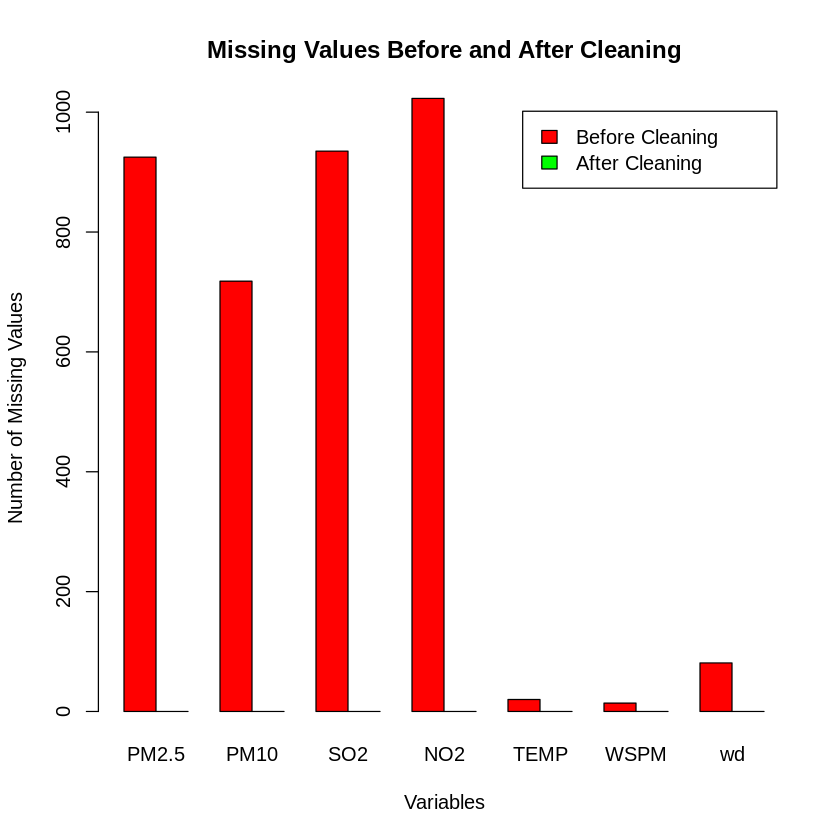

In [40]:
barplot(
  rbind(before_missing, after_missing),
  beside = TRUE,
  names.arg = c("PM2.5","PM10","SO2","NO2","TEMP","WSPM","wd"),
  col = c("red", "green"),
  main = "Missing Values Before and After Cleaning",
  xlab = "Variables",
  ylab = "Number of Missing Values",
  legend.text = c("Before Cleaning", "After Cleaning")
)

In [41]:
write.csv(
  air_data,
  "cleaned_air_quality_data.csv",
  row.names = FALSE
)